In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [17]:
df = pd.read_csv("../1-dataset/credit_risk_dataset.csv")

In [18]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [19]:
df.shape

(32581, 12)

In [20]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [21]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [22]:
print("Missing Values in Each Column:")
print(df.isnull().sum())
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values in Each Column:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

Total Missing Values: 4011


In [23]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 165


In [24]:
missing_data = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': (df.isnull().sum() / len(df)) * 100
})

print(missing_data)

                            Missing Values  Percentage
person_age                               0    0.000000
person_income                            0    0.000000
person_home_ownership                    0    0.000000
person_emp_length                      895    2.747000
loan_intent                              0    0.000000
loan_grade                               0    0.000000
loan_amnt                                0    0.000000
loan_int_rate                         3116    9.563856
loan_status                              0    0.000000
loan_percent_income                      0    0.000000
cb_person_default_on_file                0    0.000000
cb_person_cred_hist_length               0    0.000000


In [25]:
df['person_emp_length'] = df['person_emp_length'].fillna(
    df['person_emp_length'].median()
)
df['loan_int_rate'] = df['loan_int_rate'].fillna(
    df['loan_int_rate'].median()
)
print("Missing Values After Treatment:")
print(df.isnull().sum())
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values After Treatment:
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

Total Missing Values: 0


In [26]:
df = df.drop_duplicates()
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [28]:
# Calculate Q1 and Q3

Q1 = df['person_income'].quantile(0.25)
Q3 = df['person_income'].quantile(0.75)

# Calculate IQR

IQR = Q3 - Q1

# Calculate Limits

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 38542.0
Q3: 79218.0
IQR: 40676.0
Lower Limit: -22472.0
Upper Limit: 140232.0


In [29]:
outliers = df[df['person_income'] > upper_limit]

print("Total Income Outliers:", len(outliers))

Total Income Outliers: 1478


In [25]:
# Person Age
print("\nPERSON AGE")
print("Minimum:", df['person_age'].min())
print("Maximum:", df['person_age'].max())
print("Age above 100:")
print(df[df['person_age'] > 100][['person_age']])

# Person Income
print("\nPERSON INCOME")
print("Minimum:", df['person_income'].min())
print("Maximum:", df['person_income'].max())
print("Negative Income:")
print(df[df['person_income'] < 0][['person_income']])




PERSON AGE
Minimum: 20
Maximum: 144
Age above 100:
       person_age
81            144
183           144
575           123
747           123
32297         144

PERSON INCOME
Minimum: 4000
Maximum: 6000000
Negative Income:
Empty DataFrame
Columns: [person_income]
Index: []


In [26]:
# Employment Length
print("\nEMPLOYMENT LENGTH")
print("Minimum:", df['person_emp_length'].min())
print("Maximum:", df['person_emp_length'].max())
print("Employment above Age:")
print(df[df['person_emp_length'] > df['person_age']][
    ['person_age', 'person_emp_length']
])




EMPLOYMENT LENGTH
Minimum: 0.0
Maximum: 123.0
Employment above Age:
     person_age  person_emp_length
0            22              123.0
210          21              123.0


In [27]:
# Loan Amount
print("\nLOAN AMOUNT")
print("Minimum:", df['loan_amnt'].min())
print("Maximum:", df['loan_amnt'].max())
print("Zero or Negative Loan:")
print(df[df['loan_amnt'] <= 0][['loan_amnt']])




LOAN AMOUNT
Minimum: 500
Maximum: 35000
Zero or Negative Loan:
Empty DataFrame
Columns: [loan_amnt]
Index: []


In [28]:
# Interest Rate
print("\nLOAN INTEREST RATE")
print("Minimum:", df['loan_int_rate'].min())
print("Maximum:", df['loan_int_rate'].max())
print("Interest Rate above 100:")
print(df[df['loan_int_rate'] > 100][['loan_int_rate']])




LOAN INTEREST RATE
Minimum: 5.42
Maximum: 23.22
Interest Rate above 100:
Empty DataFrame
Columns: [loan_int_rate]
Index: []


In [29]:
# Loan Percent Income
print("\nLOAN PERCENT INCOME")
print("Minimum:", df['loan_percent_income'].min())
print("Maximum:", df['loan_percent_income'].max())
print("Values above 1:")
print(df[df['loan_percent_income'] > 1][
    ['loan_percent_income']
])




LOAN PERCENT INCOME
Minimum: 0.0
Maximum: 0.83
Values above 1:
Empty DataFrame
Columns: [loan_percent_income]
Index: []


In [30]:
# Credit History Length
print("\nCREDIT HISTORY LENGTH")
print("Minimum:", df['cb_person_cred_hist_length'].min())
print("Maximum:", df['cb_person_cred_hist_length'].max())
print("History Length above Age:")
print(df[df['cb_person_cred_hist_length'] > df['person_age']][
    ['person_age', 'cb_person_cred_hist_length']
])


CREDIT HISTORY LENGTH
Minimum: 2
Maximum: 30
History Length above Age:
Empty DataFrame
Columns: [person_age, cb_person_cred_hist_length]
Index: []


In [7]:
suspicious_data = df[
    (df['person_age'] > 60) |
    (df['person_emp_length'] > df['person_age'])
]

print(suspicious_data[
    ['person_age', 'person_emp_length']
])

       person_age  person_emp_length
0              22              123.0
81            144                4.0
183           144                4.0
210            21              123.0
575           123                2.0
...           ...                ...
32552          65                2.0
32557          69                3.0
32562          61               30.0
32578          65                3.0
32580          66                2.0

[72 rows x 2 columns]


In [10]:
# Condition 1: Person age greater than 100
condition_1 = df[df['person_age'] > 100]
print("Age Greater Than 100:")
print(condition_1[['person_age', 'person_emp_length']])

# Condition 2: Employment length greater than 100
condition_2 = df[df['person_emp_length'] > 100]
print("\nEmployment Length Greater Than 100:")
print(condition_2[['person_age', 'person_emp_length']])


Age Greater Than 100:
       person_age  person_emp_length
81            144                4.0
183           144                4.0
575           123                2.0
747           123                7.0
32297         144               12.0

Employment Length Greater Than 100:
     person_age  person_emp_length
0            22              123.0
210          21              123.0


In [ ]:
total_records = len(df)

# Condition 1: Age greater than 100
age_outliers = df[df['person_age'] > 100]

# Condition 2: Employment length greater than 100
employment_outliers = df[df['person_emp_length'] > 100]

# Calculate percentages
age_percentage = (len(age_outliers) / total_records) * 100

employment_percentage = (len(employment_outliers) / total_records) * 100

print("Total Records:", total_records)

print("\nAge Above 100:")
print("Outlier Count:", len(age_outliers))
print("Outlier Percentage:", round(age_percentage, 2), "%")

print("\nEmployment Length Above 100:")
print("Outlier Count:", len(employment_outliers))
print("Outlier Percentage:", round(employment_percentage, 2), "%")

Total Records: 32581

Age Above 100:
Outlier Count: 5
Outlier Percentage: 0.02 %

Employment Length Above 100:
Outlier Count: 2
Outlier Percentage: 0.01 %


In [12]:
# Age greater than 100 ko missing banana
df.loc[df['person_age'] > 100, 'person_age'] = np.nan

# Employment length greater than 100 ko missing banana
df.loc[df['person_emp_length'] > 100, 'person_emp_length'] = np.nan

In [13]:
df['person_age'] = df['person_age'].fillna(
    df['person_age'].median()
)

df['person_emp_length'] = df['person_emp_length'].fillna(
    df['person_emp_length'].median()
)

In [14]:
print("Age Missing Values:", df['person_age'].isnull().sum())

print("Employment Length Missing Values:",
      df['person_emp_length'].isnull().sum())

Age Missing Values: 0
Employment Length Missing Values: 0


In [30]:
print("Age above 100:",
      (df['person_age'] > 100).sum())

print("Employment length above 100:",
      (df['person_emp_length'] > 100).sum())

Age above 100: 5
Employment length above 100: 2


Loan Status Count:
loan_status
0    25327
1     7089
Name: count, dtype: int64

Loan Status Percentage:
loan_status
0    78.13117
1    21.86883
Name: proportion, dtype: float64


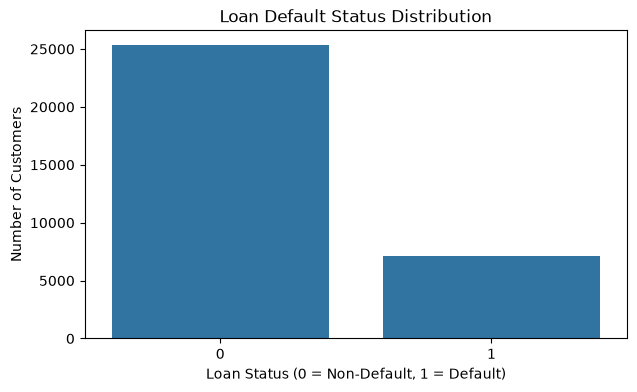

In [31]:
# Count of Loan Status
loan_status_count = df['loan_status'].value_counts()
print("Loan Status Count:")
print(loan_status_count)

# Percentage of Loan Status
loan_status_percentage = df['loan_status'].value_counts(normalize=True) * 100
print("\nLoan Status Percentage:")
print(loan_status_percentage)

# Bar Chart
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='loan_status')
plt.title("Loan Default Status Distribution")
plt.xlabel("Loan Status (0 = Non-Default, 1 = Default)")
plt.ylabel("Number of Customers")
plt.show()

In [32]:
numerical_columns = [
    'person_age',
    'person_income',
    'person_emp_length',
    'loan_amnt',
    'loan_int_rate',
    'loan_percent_income',
    'cb_person_cred_hist_length'
]

# Statistical Summary
df[numerical_columns].describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
count,32416.000000,3.241600e+04,32416.000000,32416.000000,32416.000000,32416.000000,32416.000000
mean,27.747008,6.609164e+04,4.768880,9593.845632,11.014662,0.170250,5.811297
std,6.354100,6.201558e+04,4.090411,6322.730241,3.083050,0.106812,4.059030
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,2.000000
25%,23.000000,3.854200e+04,2.000000,5000.000000,8.490000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.150000,4.000000
75%,30.000000,7.921800e+04,7.000000,12250.000000,13.110000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,0.830000,30.000000


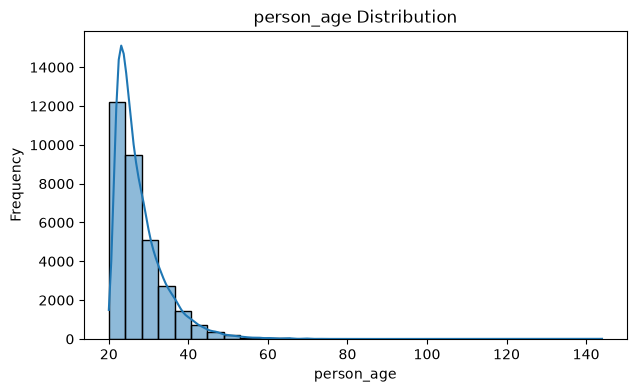

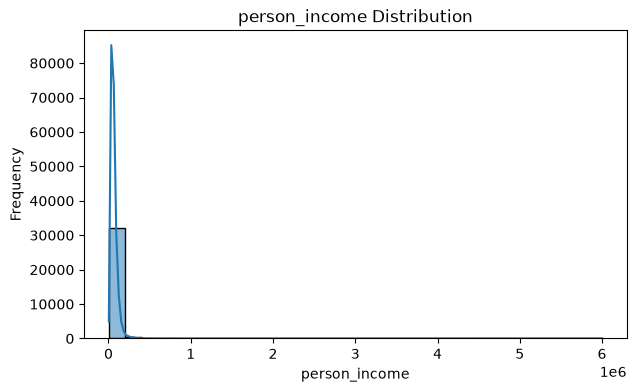

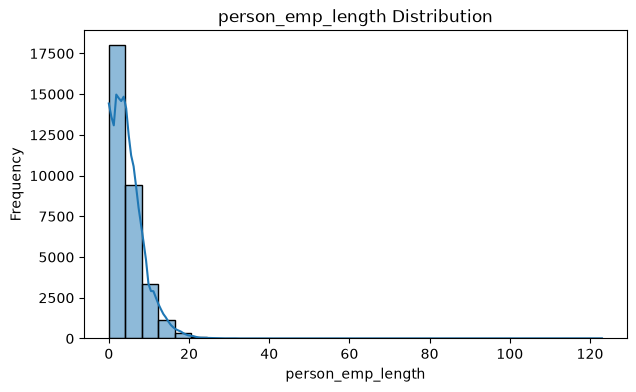

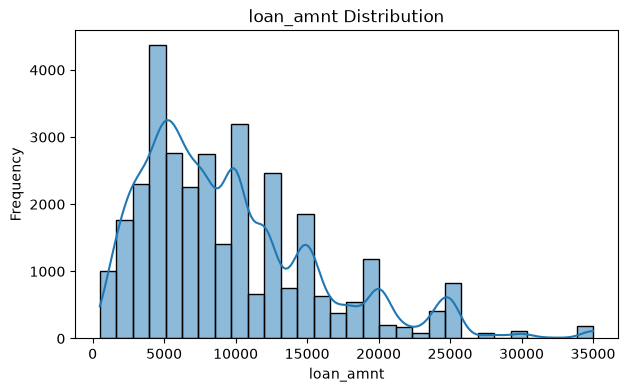

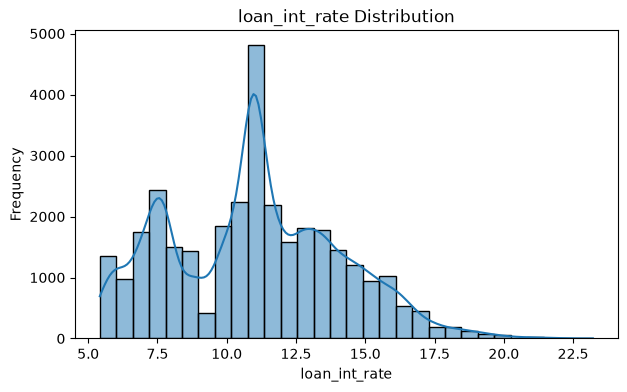

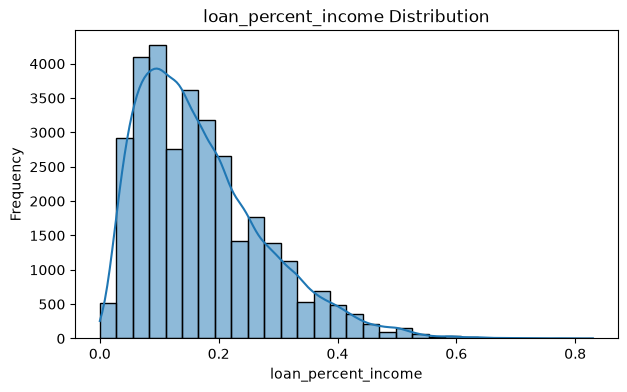

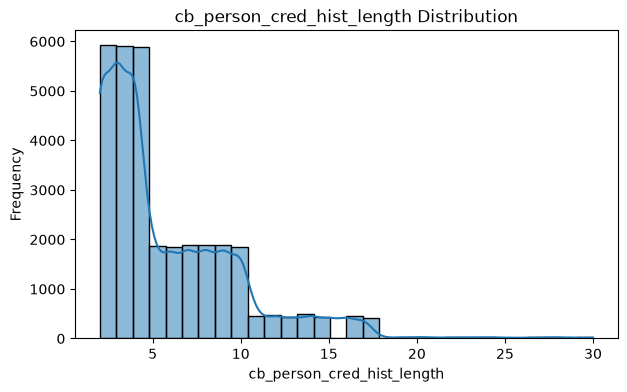

In [33]:
for column in numerical_columns:

    plt.figure(figsize=(7, 4))

    sns.histplot(df[column], bins=30, kde=True)

    plt.title(column + " Distribution")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.show()


 person_home_ownership
person_home_ownership
RENT        16378
MORTGAGE    13369
OWN          2563
OTHER         106
Name: count, dtype: int64


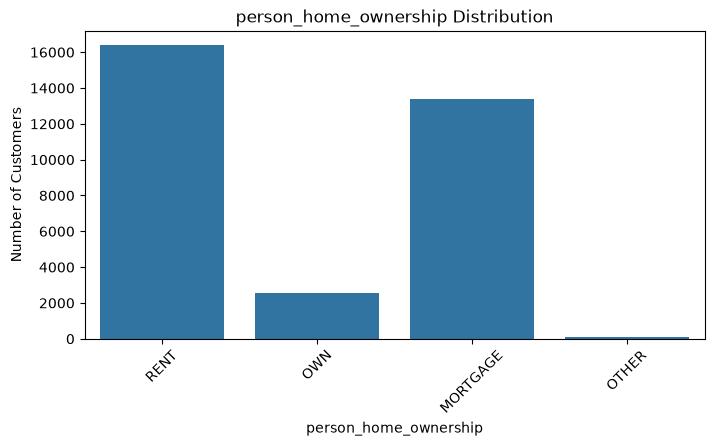


 loan_intent
loan_intent
EDUCATION            6411
MEDICAL              6042
VENTURE              5682
PERSONAL             5498
DEBTCONSOLIDATION    5189
HOMEIMPROVEMENT      3594
Name: count, dtype: int64


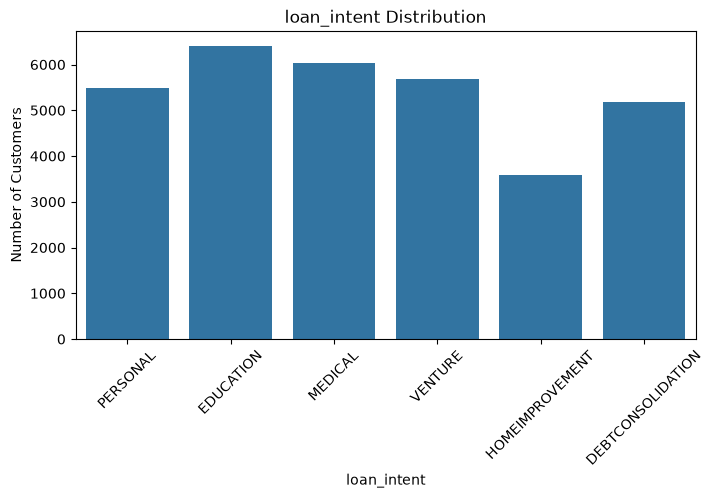


 loan_grade
loan_grade
A    10703
B    10387
C     6438
D     3620
E      963
F      241
G       64
Name: count, dtype: int64


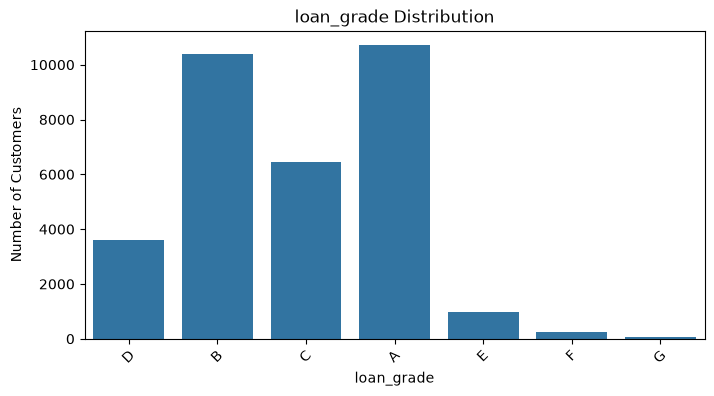


 cb_person_default_on_file
cb_person_default_on_file
N    26686
Y     5730
Name: count, dtype: int64


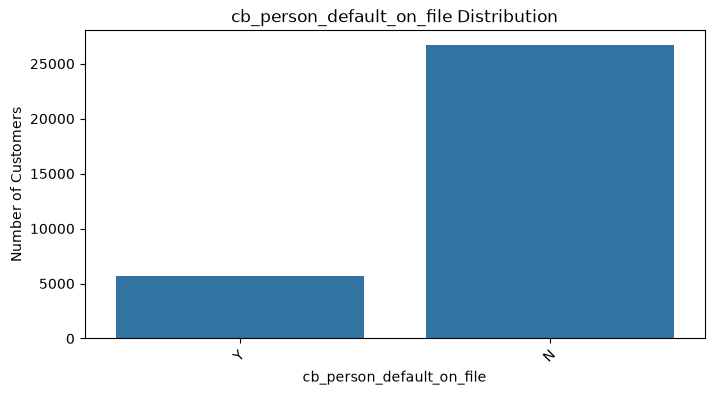

In [34]:
categorical_columns = [
    'person_home_ownership',
    'loan_intent',
    'loan_grade',
    'cb_person_default_on_file'
]

for column in categorical_columns:

    print("\n", column)
    print(df[column].value_counts())

    plt.figure(figsize=(8, 4))

    sns.countplot(data=df, x=column)

    plt.title(column + " Distribution")
    plt.xlabel(column)
    plt.ylabel("Number of Customers")

    plt.xticks(rotation=45)

    plt.show()

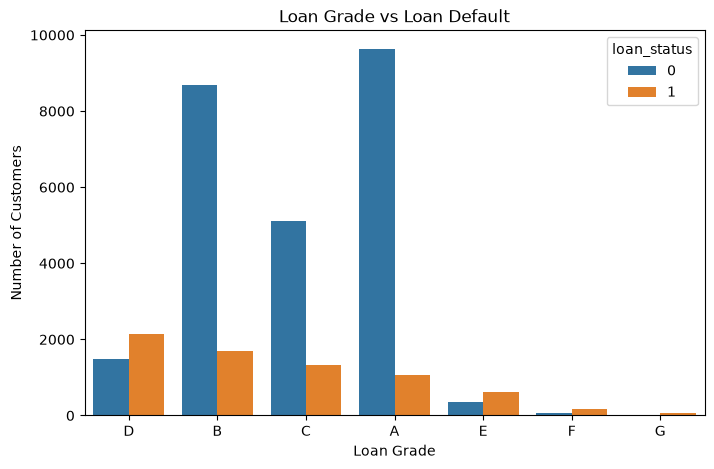

In [35]:
# Loan Grade vs Loan Status

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='loan_grade',
    hue='loan_status'
)

plt.title("Loan Grade vs Loan Default")
plt.xlabel("Loan Grade")
plt.ylabel("Number of Customers")

plt.show()

In [36]:
# Calculate Default Rate by Loan Grade

default_rate = df.groupby('loan_grade')['loan_status'].mean() * 100

print("Default Rate by Loan Grade:")
print(default_rate.round(2))

Default Rate by Loan Grade:
loan_grade
A     9.96
B    16.32
C    20.75
D    59.06
E    64.49
F    70.54
G    98.44
Name: loan_status, dtype: float64


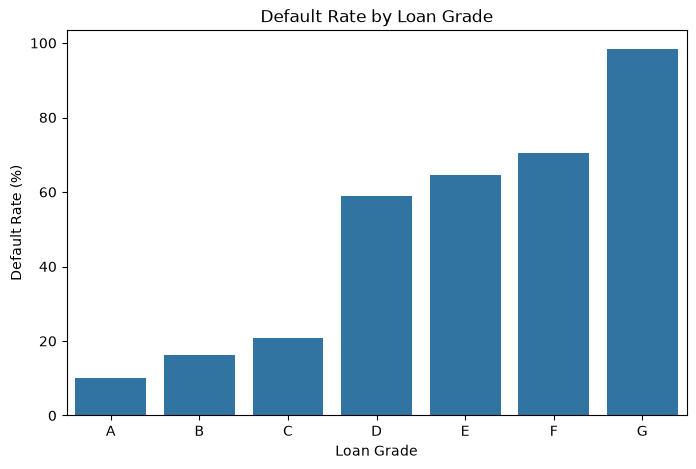

In [37]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=default_rate.index,
    y=default_rate.values
)

plt.title("Default Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")

plt.show()

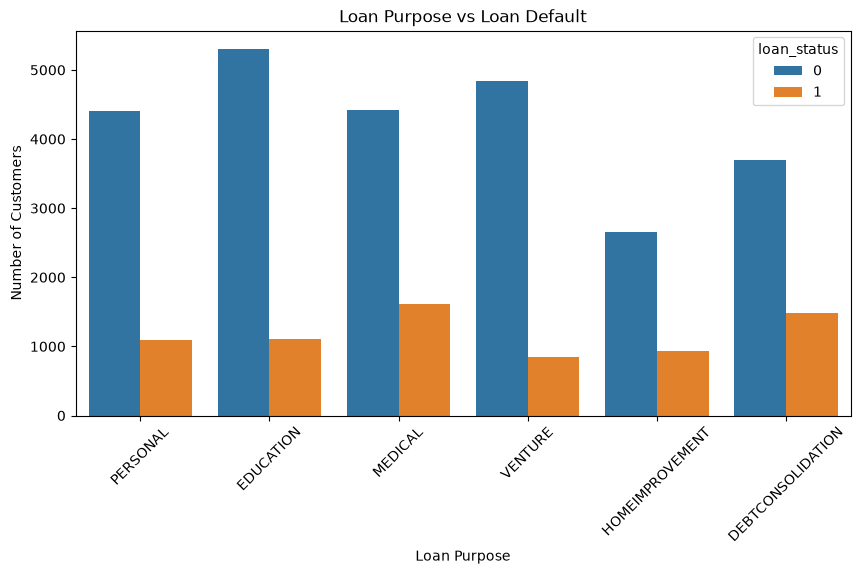

In [38]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='loan_intent',
    hue='loan_status'
)

plt.title("Loan Purpose vs Loan Default")
plt.xlabel("Loan Purpose")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

In [39]:
# Default Rate by Loan Purpose

purpose_default_rate = (
    df.groupby('loan_intent')['loan_status'].mean() * 100
)

print(purpose_default_rate.round(2))

loan_intent
DEBTCONSOLIDATION    28.68
EDUCATION            17.25
HOMEIMPROVEMENT      26.15
MEDICAL              26.76
PERSONAL             19.90
VENTURE              14.85
Name: loan_status, dtype: float64


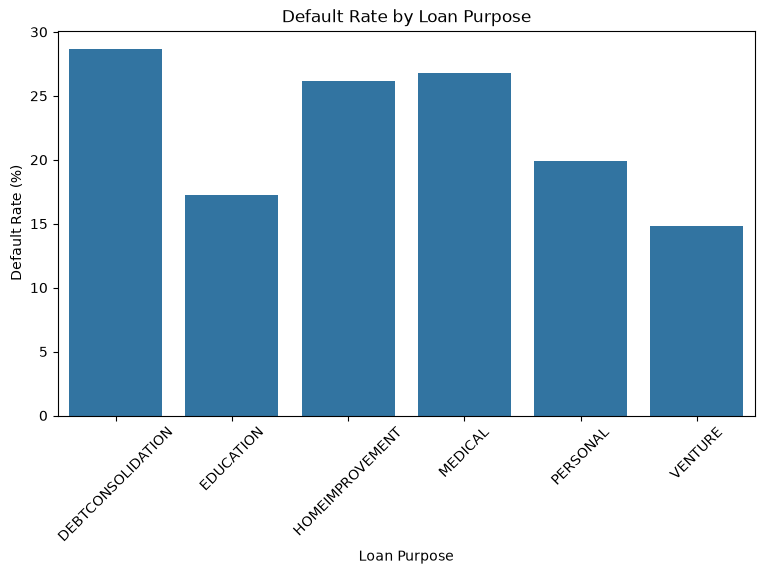

In [40]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=purpose_default_rate.index,
    y=purpose_default_rate.values
)

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)

plt.show()

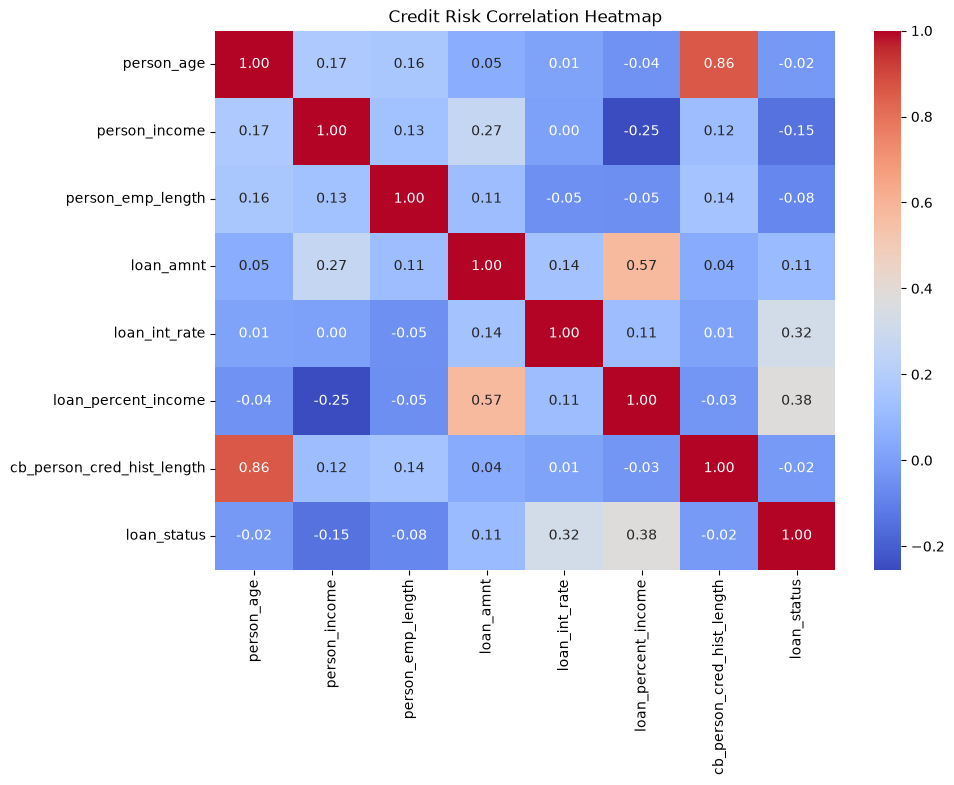

In [41]:
# Correlation Matrix
correlation = df[numerical_columns + ['loan_status']].corr()

# Heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Credit Risk Correlation Heatmap")

plt.show()